# AutoValue AI: Machine Learning-Based Used Car Price Prediction System
(Сформулируйте название самостоятельно. Постарайтесь отразить в нём суть задачи: предсказание стоимости автомобилей с учётом бизнес-рисков).

# Часть 0. Подготовка окружения

## Проверка наличия и импорт необходимых библиотек

In [1]:
import sys
import subprocess

packages = {
    "pandas": "2.2.3",
    "numpy": "1.24.4",
    "matplotlib": "3.9.2",
    "seaborn": "0.13.2",
    "scikit-learn": "1.5.2",
    "optuna": "4.0.0",
    "xgboost": "2.1.2",
    "catboost": "1.2.7",
    "lightgbm": "4.5.0",
    "shap": "0.46.0",
}

subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "--only-binary=:all:",
    *[f"{name}=={ver}" for name, ver in packages.items()]
])

0

In [2]:
# Работа с данными
import pandas as pd                   # Работа с таблицами и DataFrame
import numpy as np                    # Численные вычисления и массивы

# Визуализация данных
import matplotlib.pyplot as plt       # Построение графиков
import seaborn as sns                 # Статистическая визуализация и EDA

# Разделение данных
from sklearn.model_selection import (
    train_test_split,                   # Разделение на train и validation
    cross_val_score                 
)

# Предобработка данных
from sklearn.preprocessing import OneHotEncoder       # Кодирование категориальных признаков
from sklearn.compose import ColumnTransformer         # Разная обработка разных типов признаков

# Модели градиентного бустинга
from xgboost import XGBRegressor       # Регрессия с XGBoost
from catboost import CatBoostRegressor # Регрессия с CatBoost
from lightgbm import LGBMRegressor     # Регрессия с LightGBM

# Метрики качества регрессии
from sklearn.metrics import (
    mean_absolute_error,              # MAE — средняя абсолютная ошибка
    mean_squared_error,               # MSE / RMSE — среднеквадратичная ошибка
    r2_score                          # R² — коэффициент детерминации
)

# Оптимизация гиперпараметров
import optuna                                          # Автоматический подбор гиперпараметров

# Интерпретация моделей
import shap                            # SHAP — влияние признаков на предсказания

# Измерение производительности (необязательное задание)
import time                            # Замер времени обучения и предсказания

## Настройка констант, отоброжения графиков и таблиц

In [3]:
# Настройки графиков
sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

# Настройки отображения датафреймов
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:.3f}".format)

In [4]:
# Показываем все столбцы и полный текст внутри ячеек
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

# В длинных таблицах показываем до 100 строк
pd.set_option('display.max_rows', 100)

# Не переносим столбцы при текстовом выводе таблиц
pd.set_option('display.expand_frame_repr', False)

In [5]:
# Фиксируем случайность для воспроизводимости результатов
RANDOM_STATE = 42

## Функции, используемые в работе

In [51]:
# создаём функцию преобразования категорий
def prepare_categories(df):
    
    '''функция преобразует категории для дальнейшего обучения'''
    # список всех категориальных признаков
    cat_columns = ["fuel_type", "brand", "transmission", "color", "service_history", "insurance_valid", "region"]
    df = df.copy()
    df[cat_columns] = df[cat_columns].astype('category')
    return df, cat_columns

In [ ]:
def metrics(model, X_valid, y_valid):
    
    '''Функция расчитывает и возвращает основные и тематические метрики'''
    start_time = time.time()
    # получаем предсказания по val объектам
    y_pred = model.predict(X_valid)    
    # рассчитываем значение метрики mae
    mae = mean_absolute_error(y_valid, y_pred)
    rmse = mean_squared_error(y_valid, y_pred) ** 0.5
    r2 = r2_score(y_valid, y_pred)
    
    # расчитаем тематические метрики

    # рассчитываем относительное отклонение
    error_ratio = (y_pred - y_valid) / y_valid

    # Считаем долю тех, где отклонение выше 20%
    overpricing_rate = (error_ratio > 0.20).mean()

    # Находим маску (фильтр) для случаев занижения цены на 20%+
    under_mask = error_ratio < -0.20

    # Суммируем разницу между реальной ценой и предсказанием для этих случаев
    underpricing_loss = (y_valid[under_mask] - y_pred[under_mask]).sum()
    
    metric_time = time.time() - start_time
    
    print(f"время расчёта метрик: {metric_time:.4f} сек.")

    return mae, rmse, r2, overpricing_rate, underpricing_loss

In [ ]:
# функция оптимизации гиперпараметров
def objective(trial, model_name):
    
    '''Функция подборает гиперпараметры через OPTUNA'''
    # общие параметры
    params = {
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'n_estimators': trial.suggest_int('n_estimators', 500, 2000)
    }

    # параметры xgboost
    if model_name == 'xgboost':
        params.update({
            'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True)
        })
        model = XGBRegressor(
            **params,
            random_state=RANDOM_STATE,
            objective='reg:absoluteerror',
            enable_categorical=True,
            tree_method='hist'
        )

    # параметры catboost
    elif model_name == 'catboost':
        params.update({
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10)
        })
        params['depth'] = params.pop('max_depth')
        params['iterations'] = params.pop('n_estimators')

        model = CatBoostRegressor(
            **params,
            random_seed=RANDOM_STATE,
            loss_function='MAE',
            cat_features=cat_columns,
            logging_level='Silent'
        )

    # параметры lightgbm
    elif model_name == 'lightgbm':
        params.update({
            'num_leaves': trial.suggest_int('num_leaves', 20, 256),
            'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 1.0, log=True)
        })
        model = LGBMRegressor(
            **params,
            random_state=RANDOM_STATE,
            objective='regression_l1',
            verbosity=-1
        )

    # обучаем модель
    model.fit(X_train, y_train)

    # предсказываем на валидационной выборке
    y_pred = model.predict(X_valid)
    
    # возвращаем mae для минимизации
    return mean_absolute_error(y_valid, y_pred)

In [ ]:
# функция анализа ошибок по категориям

'''Функция анализирует ошибки по опредленным категориям'''
def category_errors(column):
    result = errors_df.groupby(column, observed=True).agg(
        count=('abs_error', 'size'),
        mae=('abs_error', 'mean'),
        overpricing_rate=('overpricing', 'mean'),
        underpricing_rate=('underpricing', 'mean')
    )

    # переводим доли ошибок в проценты
    result[['overpricing_rate', 'underpricing_rate']] *= 100

    # считаем общую долю больших ошибок
    result['high_error_rate'] = (
        result['overpricing_rate'] + result['underpricing_rate']
    )

    return result.round(2)

# **Часть 1. EDA (Экспресс-анализ данных)**

Проведите краткое исследование, чтобы лучше понимать данные.

**Задание 1.1:**

* Данные: загрузите `ds_s16_train_data.csv` (обучение) и `ds_s16_test_data.csv` (финальный тест). Обратите внимание на то, как прописать путь к данным: `/datasets/ds_s16_train_data.csv` и `/datasets/ds_s16_test_data.csv`
* Проведите краткий EDA: изучите распределение целевой переменной (`price_rub`), проверьте корреляции.

---

## Загрузка данных

In [6]:
# Загружаем данные
try:
    data_train = pd.read_csv('datasets/ds_s16_train_data.csv')
    data_test = pd.read_csv('datasets/ds_s16_test_data.csv')
except FileNotFoundError: # версия для запуска в Практикуме
    data_train = pd.read_csv('/datasets/ds_s16_train_data.csv')
    data_test = pd.read_csv('/datasets/ds_s16_test_data.csv')

In [7]:
# смотрим первые строки датасета
display(data_train.head())

# проверяем размер, пропуски и типы данных
print("размер:", data_train.shape)
print("\nпропуски:\n", data_train.isna().sum())
data_train.info()

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2002,9.700,1800,Diesel,2,Hyundai,Manual,Silver,Partial,0,No,242073,Урал
1,2004,16.100,1500,Diesel,3,Hyundai,Manual,Black,Unknown,0,No,426029,Москва
2,2005,10.510,5000,Diesel,2,Ford,Manual,Gray,Full,0,No,727050,Юг
3,2019,14.270,2000,Petrol,5,Hyundai,Manual,White,Full,1,Yes,753168,Дальний Восток
4,2015,21.720,1000,Petrol,1,Toyota,Automatic,Black,Full,0,Yes,733390,Сибирь


размер: (8000, 13)

пропуски:
 make_year             0
mileage_kmpl          0
engine_cc             0
fuel_type             0
owner_count           0
brand                 0
transmission          0
color                 0
service_history       0
accidents_reported    0
insurance_valid       0
price_rub             0
region                0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           8000 non-null   int64  
 1   mileage_kmpl        8000 non-null   float64
 2   engine_cc           8000 non-null   int64  
 3   fuel_type           8000 non-null   object 
 4   owner_count         8000 non-null   int64  
 5   brand               8000 non-null   object 
 6   transmission        8000 non-null   object 
 7   color               8000 non-null   object 
 8   service_history     8000 non-null   object

count      8000.000
mean     683647.872
std      264923.499
min       95000.000
25%      493857.000
50%      663866.000
75%      855056.000
max     1676525.000
Name: price_rub, dtype: float64


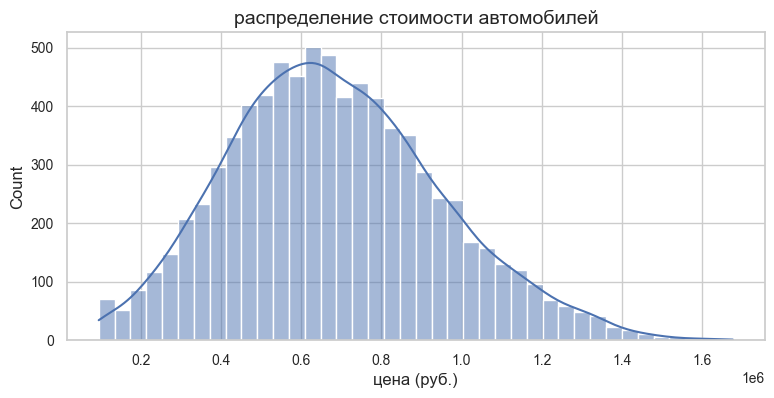

In [8]:
# выводим описательную статистику цены
print(data_train['price_rub'].describe())

# строим распределение стоимости автомобилей
plt.figure(figsize=(9, 4))
sns.histplot(data_train['price_rub'], bins=40, kde=True)
plt.title('распределение стоимости автомобилей')
plt.xlabel('цена (руб.)')
plt.show()

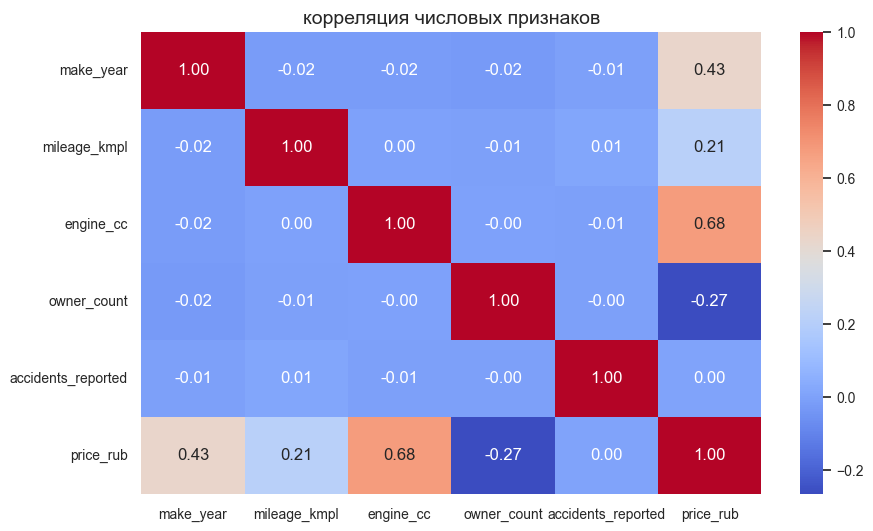

In [9]:
# рассчитываем корреляции числовых признаков
corr = data_train.select_dtypes(include='number').corr()

# строим тепловую карту корреляций
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('корреляция числовых признаков')
plt.show()

In [10]:
# сортируем признаки по силе корреляции с ценой
print(corr['price_rub'].drop('price_rub').sort_values(key=abs, ascending=False))

engine_cc             0.676
make_year             0.428
owner_count          -0.265
mileage_kmpl          0.211
accidents_reported    0.002
Name: price_rub, dtype: float64


## Выводы EDA

- Датасет содержит **8 000 записей и 13 столбцов**. Пропущенные значения отсутствуют.
- Распределение `price_rub` имеет умеренную правостороннюю асимметрию. Средняя стоимость — **683 648 ₽**, медианная — **663 866 ₽**. Диапазон цен: от 95 000 до 1 676 525 ₽.
- Наиболее сильная положительная корреляция с ценой наблюдается у `engine_cc` (**0.676**) и `make_year` (**0.428**).
- `owner_count` имеет отрицательную корреляцию (**−0.265**), `mileage_kmpl` — слабую положительную (**0.211**).
- `accidents_reported` практически не имеет линейной корреляции с ценой (**0.002**), однако это не исключает нелинейного влияния признака.

**Итог:** данные готовы к этапу предобработки. Для дальнейшего моделирования необходимо учесть числовые и категориальные признаки, сохранив одинаковые обучающие и валидационные выборки для всех трёх библиотек.

# **Часть 2. Предобработка**

На этом этапе подготовьте данные для честного соревнования библиотек. Помните: качество входных данных определяет предел точности самого мощного алгоритма.

**Задание 2.1:**

* Создайте одинаковые обучающие и валидационные наборы данных для всех трех библиотек.
* Подготовьте признаки для каждой библиотеки.
* Зафиксируйте тест: используйте файл `ds_s16_test_data.csv` как отложенную тестовую выборку.

In [40]:
# преобразуем категории и получаем список категориальных признаков
data_train, cat_columns = prepare_categories(data_train)

# проверяем типы данных
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   make_year           8000 non-null   int64   
 1   mileage_kmpl        8000 non-null   float64 
 2   engine_cc           8000 non-null   int64   
 3   fuel_type           8000 non-null   category
 4   owner_count         8000 non-null   int64   
 5   brand               8000 non-null   category
 6   transmission        8000 non-null   category
 7   color               8000 non-null   category
 8   service_history     8000 non-null   category
 9   accidents_reported  8000 non-null   int64   
 10  insurance_valid     8000 non-null   category
 11  price_rub           8000 non-null   int64   
 12  region              8000 non-null   category
dtypes: category(7), float64(1), int64(5)
memory usage: 431.1 KB


In [13]:

# разделяем признаки и целевую переменную
X = data_train.drop(columns='price_rub')
y = data_train['price_rub']

# создаём одинаковые выборки для всех моделей
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

## Выводы по предобработке

- Выделены признаки `X` и целевая переменная `price_rub`.
- Определены 7 категориальных признаков и преобразованы в тип `category`.
- Данные разделены на обучающую (6 400 записей) и валидационную (1 600 записей) выборки в соотношении 80/20 с `random_state=42`.
- Для всех трёх библиотек обеспечено одинаковое разбиение данных.
- Финальная тестовая выборка сохранена отдельно и не использовалась при предобработке.

**Итог:** данные подготовлены к обучению базовых моделей XGBoost, CatBoost и LightGBM. Специфические настройки обработки категорий будут заданы при обучении каждой модели.


# **Часть 3. Обучение моделей в разных библиотеках**

Проверьте, как алгоритмы работают из коробки. Это покажет их естественную предрасположенность к вашему набору данных до начала тонкой настройки.

**Задание 3.1:**

* Обучите XGBoost, CatBoost и LightGBM на стандартных настройках.
* Установите для всех моделей `random_state=42`. В качестве целевой функции используйте MAE.
* Обучите каждую модель
* Задача со звёздочкой: замерьте время обучения и предсказания (Wall time) с помощью `%%time` или модуля `time`.

**Задание 3.2: Сравнение метрик**

* Рассчитайте математические метрики: MAE, RMSE, $R^2$.
* Рассчитайте бизнес-риски: Overpricing Rate (>20%) и Underpricing Loss (>20%).
* Сформулируйте гипотезу: какая библиотека на этом этапе кажется наиболее безопасной для бюджета компании?

**Задача со звёздочкой: модель с использованием Quantile Loss (квантильной регрессии) в CatBoost**

Что нужно сделать:

* Выберите библиотеку `CatBoost`. Реализуйте осторожную модель через квантильный лосс.
* Вместо стандартной функции потерь (MAE) установите `loss_function='Quantile'`.
* Настройте параметр квантиля. Достаточно при инициализации модели указать: `'Quantile:alpha=значение'`. Протестируйте разные значения, выберите оптимальное.
* Сравните результаты этой осторожной модели с базовой (обученной с помощью MAE):
  1. Насколько снизился Overpricing Rate?
  2. Насколько при этом вырос Underpricing Loss?
  3. Готовы ли вы рекомендовать такую безопасную модель Артёму (CEO) вместо самой точной базовой (обученной с помощью MAE)?

---

## 3.1 Обучение моделей, подсчет метрик


In [15]:
# обучение xgb

xgb_model = XGBRegressor(random_state=RANDOM_STATE, objective='reg:absoluteerror', enable_categorical=True)
# время обучения
start_time = time.time()

xgb_model.fit(X_train, y_train)

xgboost_train_time = time.time() - start_time

xgb_mae, xgb_rmse, xgb_r2, xgb_overpricing_rate, xgb_underpricing_loss = metrics(xgb_model, X_valid, y_valid)

print(f"Значение MAE на val выборке: {xgb_mae:.2f}")
print(f"XGBoost обучен за {xgboost_train_time:.2f} секунд")

время расчёта метрик: 0.0047 сек.
Значение MAE на val выборке: 85486.97
XGBoost обучен за 0.21 секунд


In [16]:
cat_boost_model = CatBoostRegressor(random_state=RANDOM_STATE, loss_function='MAE')
# время обучения
start_time = time.time()

cat_boost_model.fit(
    X_train,
    y_train,
    cat_features=cat_columns,
    verbose=200
)
cat_boost_train_time = time.time() - start_time

(cat_boost_mae, 
 cat_boost_rmse, cat_boost_r2, 
 cat_boost_overpricing_rate, 
 cat_boost_underpricing_loss) = metrics(cat_boost_model, X_valid, y_valid)



print(f"Значение MAE на val выборке: {cat_boost_mae:.2f}")
print(f"CatBoost обучен за {cat_boost_train_time:.2f} секунд")

0:	learn: 208483.8811081	total: 60.7ms	remaining: 1m
200:	learn: 73597.9750007	total: 519ms	remaining: 2.06s
400:	learn: 70842.2333107	total: 949ms	remaining: 1.42s
600:	learn: 69298.3274299	total: 1.36s	remaining: 902ms
800:	learn: 68056.3250687	total: 1.77s	remaining: 439ms
999:	learn: 67118.1737524	total: 2.21s	remaining: 0us
время расчёта метрик: 0.0026 сек.
Значение MAE на val выборке: 79367.49
CatBoost обучен за 2.27 секунд


In [17]:
# Инициализируем LGBMRegressor
lgbm_model = LGBMRegressor(random_state=RANDOM_STATE, objective='regression_l1')

# время обучения
start_time = time.time()

# обучаем модель и передаём ей список колонок с категориальными признаками
lgbm_model.fit(
    X_train,
    y_train,
    categorical_feature=cat_columns, 
)
lgbm_model_train_time = time.time() - start_time

lgbm_mae, lgbm_rmse, lgbm_r2, lgbm_overpricing_rate, lgbm_underpricing_loss = metrics(lgbm_model, X_valid, y_valid)



print(f"Значение MAE на val выборке: {lgbm_mae:.2f}")
print(f"lgbm обучен за {lgbm_model_train_time:.2f} секунд")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000385 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 347
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 12
[LightGBM] [Info] Start training from score 662700.500000
время расчёта метрик: 0.0063 сек.
Значение MAE на val выборке: 81979.31
lgbm обучен за 0.46 секунд


**Выводы 3.1. Обучение базовых моделей**

- **CatBoost** показал наименьшую ошибку MAE - **79 367.49 ₽**, но обучался дольше остальных (2.30 с).
- **LightGBM** занял второе место по точности - **81 979.31 ₽**, время обучения — 0.45 с.
- **XGBoost** показал наибольшую ошибку - **85 486.97 ₽**, но обучился быстрее остальных (0.21 с).

**Итог:** CatBoost лидирует по точности, XGBoost - по скорости обучения.

## Задание 3.2: Сравнение метрик

In [18]:
metric_results = pd.DataFrame({
    'model_name':['xgb_model', 'cat_boost_model', 'lgbm_model'],
    'mae':[xgb_mae, cat_boost_mae, lgbm_mae],
    'rmse':[xgb_rmse, cat_boost_rmse, lgbm_rmse],
    'r2':[xgb_r2, cat_boost_r2, lgbm_r2],
    'overpricing_rate':[xgb_overpricing_rate,cat_boost_overpricing_rate, lgbm_overpricing_rate],
    'underpricing_loss':[xgb_underpricing_loss, cat_boost_underpricing_loss, lgbm_underpricing_loss]
})

metric_results

,model_name,mae,rmse,r2,overpricing_rate,underpricing_loss
0,xgb_model,85486.965,107962.627,0.828,0.144,23654384.219
1,cat_boost_model,79367.491,99047.177,0.855,0.134,16699542.262
2,lgbm_model,81979.305,102803.932,0.844,0.139,19556105.100


**Выводы 3.2. Сравнение метрик**

- **CatBoost** показал лучшие результаты: MAE - **79 367 ₽**, RMSE - **99 047 ₽**, Overpricing Rate - **13,4%**, Underpricing Loss — **16,7 млн ₽**.
- **LightGBM** занял второе место по MAE (81 979 ₽) и бизнес-рискам.
- **XGBoost** показал наибольшую ошибку MAE (85 487 ₽) и самый высокий риск переплат (14,4%).

**Итог:** на данном этапе CatBoost выглядит наиболее безопасной библиотекой для бюджета компании, поскольку обеспечивает наименьшие переплаты и упущенную выгоду.

## 3.3 модель с использованием Quantile Loss в CatBoost

In [19]:
# создадим осторожную модель 

quantile_list = [0.1, 0.2, 0.3, 0.4]

quantile_results = []


# обучаем отдельную модель для каждого квантиля
for alpha in quantile_list:
    model = CatBoostRegressor(
        random_state=RANDOM_STATE,
        loss_function=f'Quantile:alpha={alpha}',
        verbose=False
    )
    start_time = time.time()
    model.fit(X_train, y_train, cat_features=cat_columns)


    quantile_model_train_time = time.time() - start_time
    
    # рассчитываем метрики на валидационной выборке
    
    
    mae, rmse, r2, overpricing_rate, underpricing_loss = metrics(
        model, X_valid, y_valid
    )
    
    quantile_results.append({
        'alpha': alpha,
        'mae': mae,
        'overpricing_rate': overpricing_rate,
        'underpricing_loss': underpricing_loss
    })
# добавляем базовую модель catboost с mae loss для сравнения
quantile_results.insert(0, {
    'alpha': 'MAE (baseline)',
    'mae': cat_boost_mae,
    'overpricing_rate': cat_boost_overpricing_rate,
    'underpricing_loss': cat_boost_underpricing_loss
})
# сравниваем результаты
pd.DataFrame(quantile_results)


время расчёта метрик: 0.0029 сек.
время расчёта метрик: 0.0031 сек.
время расчёта метрик: 0.0026 сек.
время расчёта метрик: 0.0025 сек.


,alpha,mae,overpricing_rate,underpricing_loss
0,MAE (baseline),79367.491,0.134,16699542.262
1,0.100,130704.378,0.027,139209617.972
2,0.200,103258.845,0.051,81099298.794
3,0.300,89368.915,0.081,45497556.997
4,0.400,82552.566,0.107,29786376.969


**Выводы 3.3. Квантильная регрессия CatBoost**

- **Квантиль 0.2** снижает Overpricing Rate с **13,4% до 5,1%**, то есть более чем в 2,6 раза.
- При этом MAE увеличивается с **79 367 ₽ до 103 259 ₽**, а Underpricing Loss - с **16,7 млн ₽ до 81,1 млн ₽**.
- Квантиль 0.1 ещё сильнее снижает переплаты (2,7%), но приводит к слишком большим потерям потенциальной выручки (139,2 млн ₽).

**Итог:** квантиль **0.2** представляется подходящим компромиссом для компании с ограниченным закупочным бюджетом. Несмотря на рост недооценок, он существенно снижает риск опасных переплат и помогает защитить компанию от финансовых убытков.

# **Часть 4. Работа с параметрами модели (Тюнинг)**

Теперь ваша задача — заставить алгоритмы работать на пределе возможностей, подбирая ключи к их гиперпараметрам. Чтобы сравнение было объективным, используйте единую стратегию поиска для всех библиотек.

**Задание 4.1:**

* Настройте поиск в Optuna для каждой модели.
* Использьзуйте сетку параметров, предложенную в описании проекта:
  1. **Общая сетка для всех моделей:**
    * Скорость обучения (`learning_rate/eta`): от `0.01` до `0.1, log=True`.
    * Глубина дерева (`max_depth/depth`): от `3` до `10`.
    * Количество итераций (`n_estimators/iterations`): зафиксируйте в диапазоне `500–2000`.
  2. **Специфические параметры (регуляризация):**
  * Для XGBoost: добавьте параметры `gamma` (от `1e-8` до `1.0`) и `reg_lambda/reg_alpha`(от `1e-8` до `10.0`).
  * Для CatBoost: используйте `l2_leaf_reg` (от `1` до `10`).
  * Для LightGBM: добавьте `num_leaves` (от `20` до `256`) и `min_child_samples` (от `5` до `100`); `reg_alpha` и `reg_lambda` от `1e-8` до `1.0`.
  3. Не забудьте `"random_seed": 42` и `MAE` .

* Проведите поиск гиперпараметров с помощью Optuna.
---


## Задание 4.1: подобор параметров

In [ ]:
# создаём отдельные исследования для каждой библиотеки
studies = {}

for model_name in ['xgboost', 'catboost', 'lightgbm']:
    study = optuna.create_study(
        direction='minimize',
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE)
    )
    # отключаем информационные сообщения об испытаниях
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    
    study.optimize(
        lambda trial: objective(trial, model_name),
        n_trials=30
    )

    studies[model_name] = study

    print(f"{model_name}: best MAE = {study.best_value:.2f}")
    print(f"best params: {study.best_params}\n")

[I 2026-11-05 18:03:15,778] A new study created in memory with name: no-name-06a919bc-2df5-4fa9-9d9f-4383517d3db7
[I 2026-11-05 18:03:21,697] Trial 0 finished with value: 84166.8086328125 and parameters: {'learning_rate': 0.023688639503640783, 'max_depth': 10, 'n_estimators': 1598, 'gamma': 0.0006155564318973012, 'reg_alpha': 2.5361081166471375e-07, 'reg_lambda': 2.5348407664333426e-07}. Best is trial 0 with value: 84166.8086328125.
[I 2026-11-05 18:03:25,862] Trial 1 finished with value: 84064.55504882813 and parameters: {'learning_rate': 0.011430983876313222, 'max_depth': 9, 'n_estimators': 1402, 'gamma': 0.004619347374377372, 'reg_alpha': 1.5320059381854043e-08, 'reg_lambda': 5.360294728728285}. Best is trial 1 with value: 84064.55504882813.
[I 2026-11-05 18:03:26,998] Trial 2 finished with value: 81439.90255371094 and parameters: {'learning_rate': 0.06798962421591129, 'max_depth': 4, 'n_estimators': 772, 'gamma': 2.9324868872723725e-07, 'reg_alpha': 5.472429642032198e-06, 'reg_lamb

xgboost: best MAE = 80344.24
best params: {'learning_rate': 0.015388087593961024, 'max_depth': 3, 'n_estimators': 1558, 'gamma': 1.538919573529767e-06, 'reg_alpha': 0.6565461431026351, 'reg_lambda': 0.05604782967688487}

0:	learn: 209213.8514925	total: 7.09ms	remaining: 11.3s
1:	learn: 205425.9523919	total: 11.9ms	remaining: 9.52s
2:	learn: 201673.6097841	total: 16.2ms	remaining: 8.61s
3:	learn: 198177.9828295	total: 20.3ms	remaining: 8.08s
4:	learn: 194658.9012425	total: 24.2ms	remaining: 7.71s
5:	learn: 191326.8586363	total: 28.3ms	remaining: 7.51s
6:	learn: 187824.1953873	total: 33.7ms	remaining: 7.67s
7:	learn: 184810.1255126	total: 37.1ms	remaining: 7.37s
8:	learn: 181651.6274401	total: 43ms	remaining: 7.59s
9:	learn: 178550.8052546	total: 48.1ms	remaining: 7.64s
10:	learn: 175564.1524096	total: 53.6ms	remaining: 7.73s
11:	learn: 172525.8058122	total: 59ms	remaining: 7.8s
12:	learn: 170206.1163334	total: 60.7ms	remaining: 7.4s
13:	learn: 167694.9803784	total: 63.1ms	remaining: 7.1

[I 2026-11-05 18:04:41,270] Trial 0 finished with value: 80239.98977682044 and parameters: {'learning_rate': 0.023688639503640783, 'max_depth': 10, 'n_estimators': 1598, 'l2_leaf_reg': 6.387926357773329}. Best is trial 0 with value: 80239.98977682044.


1582:	learn: 42754.6177806	total: 8.97s	remaining: 85ms
1583:	learn: 42753.7486904	total: 8.97s	remaining: 79.3ms
1584:	learn: 42750.2549485	total: 8.98s	remaining: 73.6ms
1585:	learn: 42745.1877210	total: 8.98s	remaining: 68ms
1586:	learn: 42733.5168948	total: 8.99s	remaining: 62.3ms
1587:	learn: 42717.1577644	total: 8.99s	remaining: 56.6ms
1588:	learn: 42713.1047109	total: 9s	remaining: 51ms
1589:	learn: 42710.7104324	total: 9s	remaining: 45.3ms
1590:	learn: 42708.4599789	total: 9.01s	remaining: 39.6ms
1591:	learn: 42707.2353753	total: 9.02s	remaining: 34ms
1592:	learn: 42688.4645025	total: 9.02s	remaining: 28.3ms
1593:	learn: 42686.9767104	total: 9.02s	remaining: 22.6ms
1594:	learn: 42672.1752061	total: 9.03s	remaining: 17ms
1595:	learn: 42663.5910777	total: 9.04s	remaining: 11.3ms
1596:	learn: 42625.5949502	total: 9.04s	remaining: 5.66ms
1597:	learn: 42618.3802181	total: 9.05s	remaining: 0us
0:	learn: 211284.3959830	total: 3.95ms	remaining: 2.32s
1:	learn: 209382.6995885	total: 5.8

[I 2026-11-05 18:04:42,254] Trial 1 finished with value: 79659.27136296118 and parameters: {'learning_rate': 0.014322493718230255, 'max_depth': 4, 'n_estimators': 587, 'l2_leaf_reg': 8.795585311974417}. Best is trial 1 with value: 79659.27136296118.


503:	learn: 74864.9630592	total: 824ms	remaining: 136ms
504:	learn: 74859.2733731	total: 826ms	remaining: 134ms
505:	learn: 74853.7712263	total: 827ms	remaining: 132ms
506:	learn: 74851.4213725	total: 828ms	remaining: 131ms
507:	learn: 74842.3493323	total: 830ms	remaining: 129ms
508:	learn: 74835.7575679	total: 831ms	remaining: 127ms
509:	learn: 74827.9152213	total: 833ms	remaining: 126ms
510:	learn: 74824.6081885	total: 834ms	remaining: 124ms
511:	learn: 74816.9682106	total: 836ms	remaining: 122ms
512:	learn: 74810.0305116	total: 838ms	remaining: 121ms
513:	learn: 74807.2250226	total: 838ms	remaining: 119ms
514:	learn: 74802.9451260	total: 840ms	remaining: 117ms
515:	learn: 74798.0569260	total: 842ms	remaining: 116ms
516:	learn: 74791.7991591	total: 843ms	remaining: 114ms
517:	learn: 74783.1224294	total: 845ms	remaining: 113ms
518:	learn: 74776.5150074	total: 846ms	remaining: 111ms
519:	learn: 74771.1926689	total: 848ms	remaining: 109ms
520:	learn: 74768.1278884	total: 849ms	remaining

... (112 outputs left out)

[I 2026-11-05 18:08:06,628] Trial 28 finished with value: 81076.94934779109 and parameters: {'learning_rate': 0.01054081939144372, 'max_depth': 3, 'n_estimators': 731, 'num_leaves': 74, 'min_child_samples': 85, 'reg_alpha': 0.0001166412916275137, 'reg_lambda': 2.7383948321754615e-05}. Best is trial 21 with value: 80113.65937051189.


[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No f

[I 2026-11-05 18:08:18,596] Trial 29 finished with value: 82638.7686742512 and parameters: {'learning_rate': 0.027079337426445353, 'max_depth': 9, 'n_estimators': 1626, 'num_leaves': 159, 'min_child_samples': 65, 'reg_alpha': 0.020806983286552002, 'reg_lambda': 0.004216321339592419}. Best is trial 21 with value: 80113.65937051189.


lightgbm: best MAE = 80113.66
best params: {'learning_rate': 0.019295838462462044, 'max_depth': 3, 'n_estimators': 1165, 'num_leaves': 43, 'min_child_samples': 73, 'reg_alpha': 0.055916675709795284, 'reg_lambda': 0.02349720945611265}



In [22]:
# собираем лучшие результаты optuna для каждой модели
best_results = pd.DataFrame([
    {
        'model': name,
        'best_mae': study.best_value,
        'best_params': study.best_params
    }
    for name, study in studies.items()
])

# сортируем модели по минимальной ошибке mae
best_results = best_results.sort_values('best_mae').reset_index(drop=True)

display(best_results)

,model,best_mae,best_params
0,catboost,79167.988,"{'learning_rate': 0.06798962421591129, 'max_depth': 4, 'n_estimators': 772, 'l2_leaf_reg': 2.650640588680904}"
1,lightgbm,80113.659,"{'learning_rate': 0.019295838462462044, 'max_depth': 3, 'n_estimators': 1165, 'num_leaves': 43, 'min_child_samples': 73, 'reg_alpha': 0.055916675709795284, 'reg_lambda': 0.02349720945611265}"
2,xgboost,80344.237,"{'learning_rate': 0.015388087593961024, 'max_depth': 3, 'n_estimators': 1558, 'gamma': 1.538919573529767e-06, 'reg_alpha': 0.6565461431026351, 'reg_lambda': 0.05604782967688487}"


In [28]:
# получаем лучшие параметры catboost и переименовываем их
cat_params = studies['catboost'].best_params.copy()
cat_params['depth'] = cat_params.pop('max_depth')
cat_params['iterations'] = cat_params.pop('n_estimators')

# создаём оптимизированные модели
best_models = {
    'xgboost': XGBRegressor(**studies['xgboost'].best_params, random_state=RANDOM_STATE, objective='reg:absoluteerror', enable_categorical=True, tree_method='hist'),
    'catboost': CatBoostRegressor(**cat_params, random_seed=RANDOM_STATE, loss_function='MAE', cat_features=cat_columns, logging_level='Silent'),
    'lightgbm': LGBMRegressor(**studies['lightgbm'].best_params, random_state=RANDOM_STATE, objective='regression_l1', verbosity=-1)
}


# обучаем модели и измеряем время
for name, model in best_models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    best_study_time = time.time() - start_time

    print(f"время обучения {name}: {best_study_time:.4f} сек.")

время обучения xgboost: 2.0516 сек.
время обучения catboost: 1.2487 сек.
время обучения lightgbm: 1.0803 сек.


## Выводы 4 Оптимизация гиперпараметров



Для каждой из трёх библиотек проведено по **30 испытаний Optuna** с минимизацией MAE на одинаковой валидационной выборке.

| Модель | MAE до оптимизации | MAE после | Улучшение |
|---|---:|---:|---:|
| CatBoost | 79 367 ₽ | 79 168 ₽ | 199 ₽ |
| LightGBM | 81 979 ₽ | 80 114 ₽ | 1 866 ₽ |
| XGBoost | 85 487 ₽ | 80 344 ₽ | 5 143 ₽ |

- **CatBoost** сохранил лидерство по точности, хотя улучшение оказалось минимальным (0,25%).
- **LightGBM** снизил ошибку на 2,28%.
- **XGBoost** получил наибольший прирост качества — MAE уменьшилась на 6,02%.

Время обучения оптимизированных моделей составило: XGBoost — 2,05 с, CatBoost — 1,25 с, LightGBM — 1,08 с.

**Итог:** оптимизация улучшила качество всех трёх алгоритмов и значительно сократила разницу между ними. CatBoost остаётся лидером по MAE, однако для окончательного выбора необходимо сравнить бизнес-риски и интерпретируемость моделей на следующем этапе.

# **Часть 5. Интерпретация и бизнес-анализ**

Модель должна быть прозрачной. Ваша задача — убедиться, что алгоритм принимает решения на основе рыночных факторов, а не случайных корреляций.

**Задание 5.1:**

* Постройте SHAP Summary Plot для оптимизированных моделей после поиска Optuna.
* Проанализируйте:
  1. Какие Топ-5 признаков вносят наибольший вклад в цену автомобиля?
  2. Совпадают ли выводы модели с бизнес-логикой?
  3. Как специфические признаки (например, color или insurance_valid) влияют на предсказание?

**Задание 5.2**

Используйте введённые метрики Overpricing Rate и Underpricing Loss:
* Рассчитайте долю завышений и недооценок для каждой модели.
* Сравните модели не только по MAE и RMSE, но и по бизнес-рискам.

**Задание 5.3**

* Проанализируйте ошибки в разрезе категорий (марки автомобилей и макро-регионов).
* Выявите марки машин и регионы, где риск ошибки высок — это зоны, где в будущем потребуется ручная проверка экспертом.

---

## Задание 5.1: SHAP анализ

xgboost


,feature,importance
2,engine_cc,0.311
3,fuel_type,0.221
4,owner_count,0.175
0,make_year,0.149
1,mileage_kmpl,0.059
5,brand,0.016
7,color,0.016
11,region,0.013
9,accidents_reported,0.011
10,insurance_valid,0.010


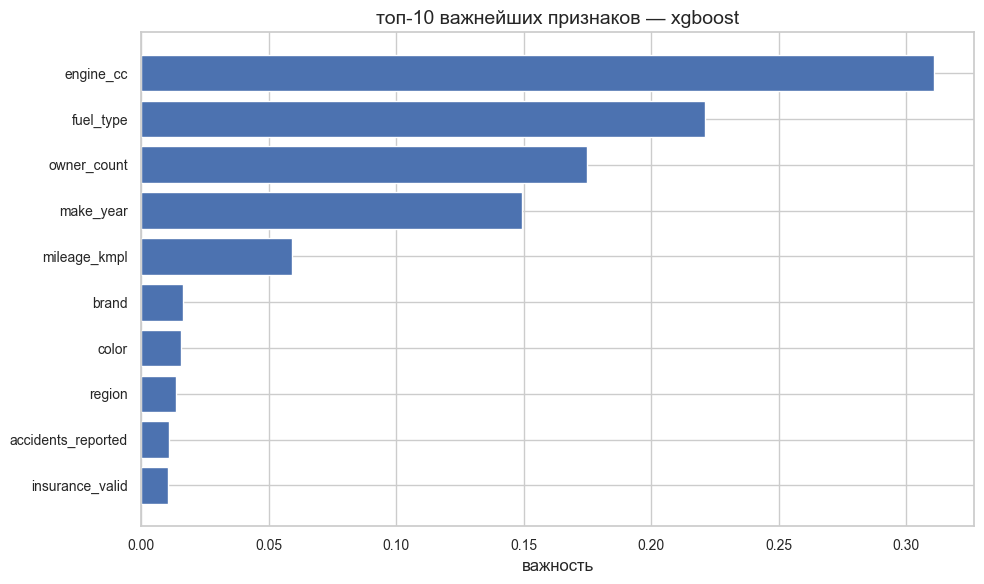

catboost


,feature,importance
2,engine_cc,47.236
0,make_year,23.839
3,fuel_type,13.270
4,owner_count,7.736
1,mileage_kmpl,6.297
5,brand,0.384
7,color,0.370
8,service_history,0.362
11,region,0.327
9,accidents_reported,0.098


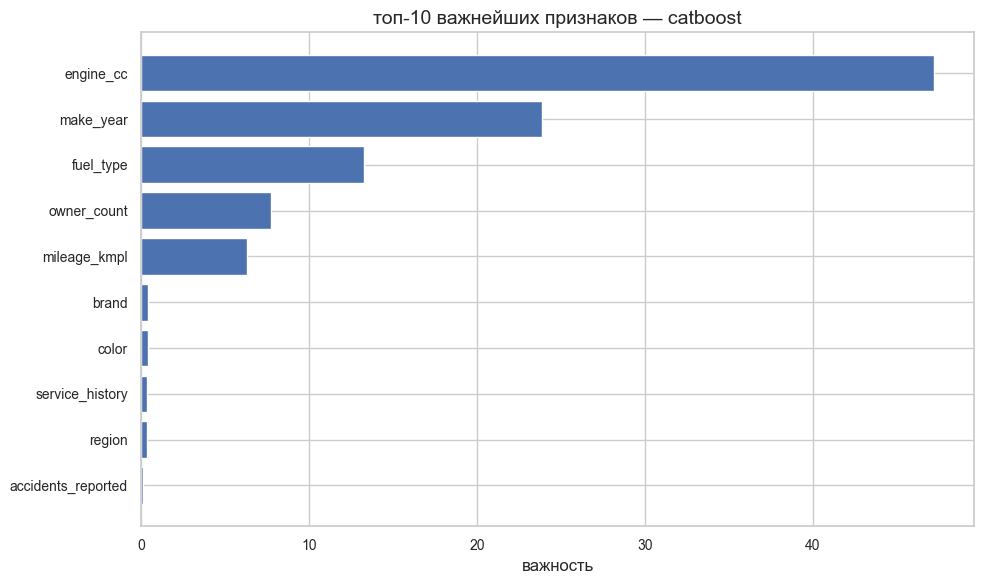

lightgbm


,feature,importance
1,mileage_kmpl,1574
0,make_year,1386
5,brand,961
2,engine_cc,928
4,owner_count,582
7,color,483
3,fuel_type,401
11,region,394
9,accidents_reported,256
8,service_history,161


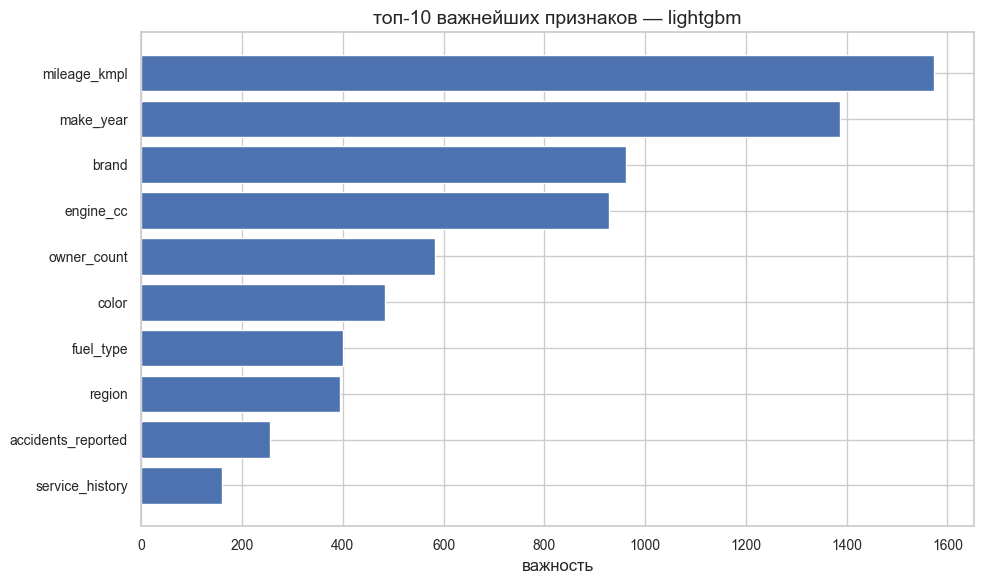

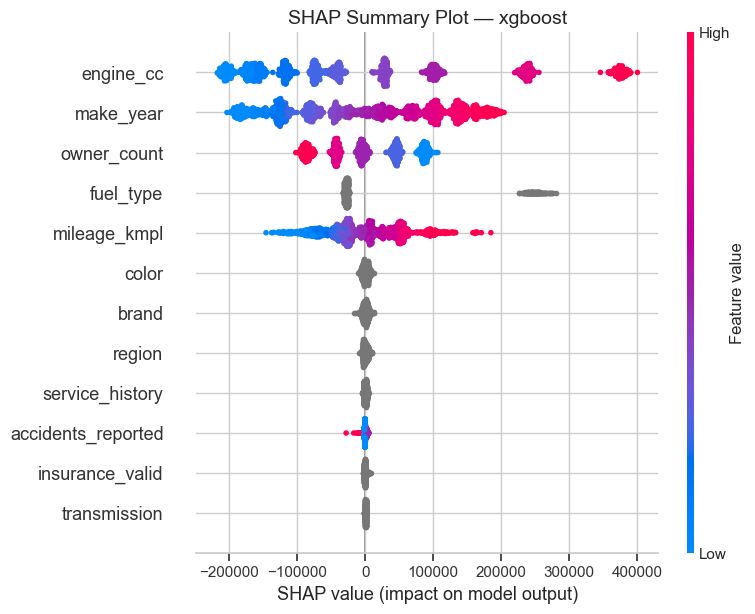

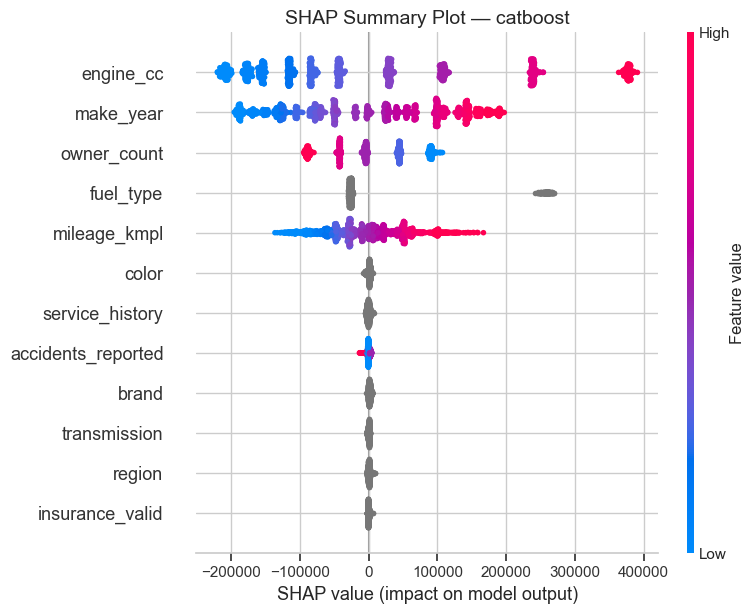

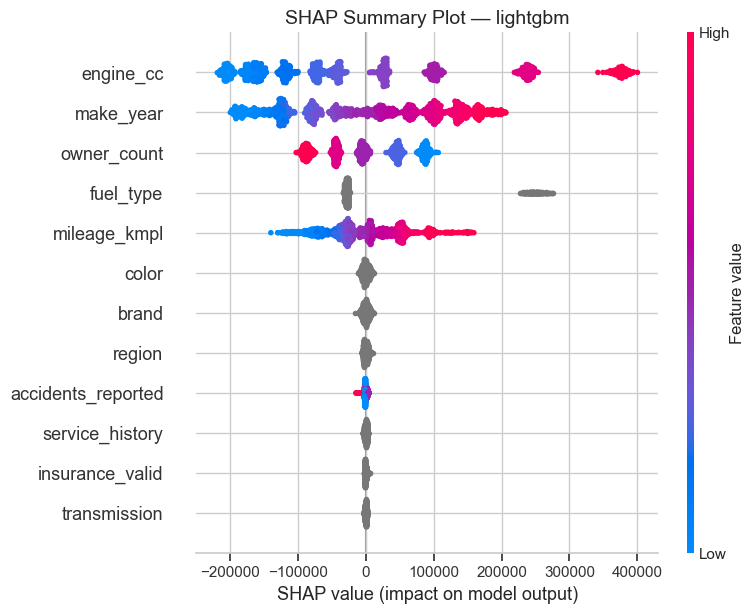

In [32]:
import xgboost as xgb

# сохраняем важность признаков каждой модели
feature_importance = {}

for name, model in best_models.items():
    feature_importance[name] = pd.DataFrame({
        'feature': X_valid.columns,
        'importance': model.feature_importances_
    }).sort_values('importance', ascending=False)

# выводим топ-10 признаков каждой модели
for name, df in feature_importance.items():
    top_10_features = df.head(10)

    print(name)
    display(top_10_features)

    # строим график важности признаков
    plt.figure(figsize=(10, 6))
    plt.barh(top_10_features['feature'][::-1], top_10_features['importance'][::-1])
    plt.xlabel('важность')
    plt.title(f'топ-10 важнейших признаков — {name}')
    plt.tight_layout()
    plt.show()

# вычисляем shap values для каждой оптимизированной модели
for name, model in best_models.items():

    # для xgboost с категориальными признаками используем нативный shap
    if name == 'xgboost':
        dmatrix = xgb.DMatrix(X_valid, enable_categorical=True)
        shap_values = model.get_booster().predict(dmatrix, pred_contribs=True)[:, :-1]

    else:
        explainer = shap.TreeExplainer(model)
        shap_values = explainer.shap_values(X_valid)

    # строим shap summary plot
    plt.figure(figsize=(10, 8))
    shap.summary_plot(shap_values, X_valid, show=False)
    plt.title(f'SHAP Summary Plot — {name}')
    plt.tight_layout()
    plt.show()

**Выводы 5.1. Интерпретация признаков (SHAP)**

Анализ SHAP показал, что все три оптимизированные модели выделяют практически одинаковые **топ-5 признаков**:

1. **engine_cc** — объём двигателя. Чем больше двигатель, тем выше прогнозируемая стоимость.
2. **make_year** — год выпуска. Более новые автомобили оцениваются дороже.
3. **owner_count** — количество владельцев. Увеличение числа владельцев снижает прогнозируемую цену.
4. **fuel_type** — тип топлива. Существенно влияет на стоимость, однако направление эффекта зависит от категории.
5. **mileage_kmpl** — топливная экономичность. Более высокие значения связаны с увеличением прогнозируемой цены.

**Соответствие бизнес-логике:** основные закономерности выглядят обоснованными: характеристики двигателя, возраст автомобиля и история владения влияют на рыночную стоимость.

**Специфические признаки:** `color`, `insurance_valid`, `service_history` и `region` оказывают сравнительно небольшое влияние на прогнозы. Особенно слабый вклад наблюдается у `insurance_valid`.

**Итог:** все три модели демонстрируют схожую логику прогнозирования, опираясь преимущественно на технические характеристики и возраст автомобиля. Существенных противоречий с бизнес-логикой не обнаружено.

## 5.2 Сравнение метрик и бизнес-рисков

In [35]:
# сравниваем оптимизированные модели
results_52 = pd.DataFrame([
    (
        name,
        *metrics(model, X_valid, y_valid),
        ((model.predict(X_valid) - y_valid.to_numpy()) / y_valid.to_numpy() < -0.20).mean()
    )
    for name, model in best_models.items()
], columns=[
    'model', 'mae', 'rmse', 'r2',
    'overpricing_rate', 'underpricing_loss', 'underpricing_rate'
])

# сортируем по mae и выводим результаты
results_52 = results_52.sort_values('mae').reset_index(drop=True)
display(results_52.round(3))

время расчёта метрик: 0.0235 сек.
время расчёта метрик: 0.0067 сек.
время расчёта метрик: 0.0135 сек.


,model,mae,rmse,r2,overpricing_rate,underpricing_loss,underpricing_rate
0,catboost,79167.988,98881.791,0.856,0.132,17645278.863,0.068
1,lightgbm,80113.659,100823.711,0.850,0.132,19258753.908,0.071
2,xgboost,80344.237,101037.535,0.849,0.138,20106050.289,0.074


**Выводы 5.2. Сравнение метрик и бизнес-рисков**

- **CatBoost** показал лучшие результаты: MAE — **79 168 ₽**, R² — **0,856**, Overpricing Rate — **13,2%**, Underpricing Loss — **17,65 млн ₽**.
- **LightGBM** немного уступает: MAE — 80 114 ₽, риск переплаты — 13,2%, упущенная выгода — 19,26 млн ₽.
- **XGBoost** показал наибольшие риски: Overpricing Rate — 13,8%, Underpricing Loss — 20,11 млн ₽.

**Итог:** CatBoost остаётся наиболее предпочтительной моделью, поскольку обеспечивает лучшую точность, минимальную долю недооценок (6,8%) и наименьшие потенциальные финансовые потери.

## 5.3. Анализ ошибок по маркам и регионам

In [36]:
# выбираем лучшую оптимизированную модель
best_name = results_52.iloc[0]['model']
model = best_models[best_name]

# получаем предсказания и реальные значения
y_pred = model.predict(X_valid)
y_true = y_valid.to_numpy()

# создаём таблицу ошибок
errors_df = X_valid[['brand', 'region']].copy()

errors_df['abs_error'] = np.abs(y_true - y_pred)

# рассчитываем относительную ошибку
error_ratio = (y_pred - y_true) / y_true

# отмечаем завышения и недооценки более 20%
errors_df['overpricing'] = error_ratio > 0.20
errors_df['underpricing'] = error_ratio < -0.20

print(f'анализируемая модель: {best_name}')

анализируемая модель: catboost


In [ ]:
# рассчитываем ошибки по маркам и регионам
brand_errors = category_errors('brand')
region_errors = category_errors('region')

display(brand_errors.sort_values('mae', ascending=False))
display(region_errors.sort_values('mae', ascending=False))

In [38]:
# выявляем категории с высоким риском ошибок
for name, df in [('марки', brand_errors), ('регионы', region_errors)]:

    # исключаем категории с менее чем 20 наблюдениями
    risky = df[df['count'] >= 20]

    print(f'\n{name}: наибольшая доля ошибок свыше 20%')

    display(
        risky.sort_values('high_error_rate', ascending=False).head(10)
    )


марки: наибольшая доля ошибок свыше 20%


,count,mae,overpricing_rate,underpricing_rate,high_error_rate
brand,,,,,
Toyota,152,85801.340,17.760,7.890,25.660
BMW,171,86604.720,11.700,11.700,23.390
Tesla,163,86231.470,14.720,8.590,23.310
Volkswagen,173,76346.310,15.610,6.940,22.540
Ford,147,77127.680,14.970,4.760,19.730
Chevrolet,159,71010.980,11.950,6.290,18.240
Hyundai,166,76986.890,12.050,6.020,18.070
Nissan,170,75007.990,11.760,5.880,17.650
Kia,167,83779.350,10.180,5.990,16.170



регионы: наибольшая доля ошибок свыше 20%


,count,mae,overpricing_rate,underpricing_rate,high_error_rate
region,,,,,
Сибирь,253,81339.870,16.210,6.320,22.530
СПб,267,78573.200,12.730,9.360,22.100
Юг,293,76760.200,13.990,7.170,21.160
Урал,276,81472.760,15.580,4.350,19.930
Москва,249,76203.920,12.850,6.020,18.880
Дальний Восток,262,80758.600,7.630,7.630,15.270


## Выводы 5.3. Анализ ошибок по маркам и регионам


**По маркам автомобилей:**
- **Toyota** имеет наибольшую долю существенных ошибок - **25,66%**, включая 17,76% завышений стоимости.
- **BMW** и **Tesla** показывают самые высокие MAE - 86 605 ₽ и 86 231 ₽ соответственно.
- **Honda** демонстрирует наименьшую MAE (71 235 ₽) и минимальную долю ошибок свыше 20% (14,39%).

**По регионам:**
- **Урал** имеет наибольшую MAE - 81 473 ₽.
- **Сибирь** лидирует по доле существенных ошибок - 22,53%, из которых 16,21% составляют завышения.
- **СПб** выделяется высокой долей недооценок - 9,36%.
- **Дальний Восток** показывает минимальную долю существенных ошибок - 15,27%.

**Итог:** модель демонстрирует неоднородное качество прогнозирования. В первую очередь ручную проверку рекомендуется проводить для автомобилей Toyota, BMW и Tesla, а также для сделок в Сибири, на Урале и в СПб. Это позволит снизить риск финансовых потерь в наиболее проблемных категориях.

---




## Общие выводы по части 5. Интерпретация и бизнес-анализ



Анализ трёх оптимизированных моделей — XGBoost, CatBoost и LightGBM — позволил оценить не только точность прогнозирования стоимости автомобилей, но и логику принятия решений, потенциальные финансовые риски и категории автомобилей, требующие особого внимания.

**1. Интерпретируемость моделей (SHAP)**

Все три алгоритма выделяют практически одинаковые пять ключевых факторов: объём двигателя (`engine_cc`), год выпуска (`make_year`), количество владельцев (`owner_count`), тип топлива (`fuel_type`) и топливную экономичность (`mileage_kmpl`).

Основные зависимости соответствуют бизнес-логике: более новые автомобили и машины с большим объёмом двигателя обычно оцениваются дороже, тогда как увеличение количества владельцев снижает прогнозируемую стоимость.

Признаки `color`, `insurance_valid`, `service_history` и `region` оказывают значительно меньшее влияние. Это говорит о том, что модели преимущественно опираются на технические характеристики автомобилей, а не второстепенные факторы.

**2. Сравнение точности и финансовых рисков**

Лучшие результаты продемонстрировал **CatBoost**:

| Метрика | CatBoost | LightGBM | XGBoost |
|---|---:|---:|---:|
| MAE, ₽ | **79 168** | 80 114 | 80 344 |
| RMSE, ₽ | **98 882** | 100 824 | 101 038 |
| R² | **0,856** | 0,850 | 0,849 |
| Завышения более 20% | **13,2%** | **13,2%** | 13,8% |
| Недооценки более 20% | **6,8%** | 7,1% | 7,4% |
| Underpricing Loss | **17,65 млн ₽** | 19,26 млн ₽ | 20,11 млн ₽ |

CatBoost обеспечивает наименьшую ошибку прогнозирования и минимальные риски недооценки. Однако даже лучшая модель существенно завышает стоимость примерно в 13% случаев.

Суммарная упущенная выгода в 17,65 млн ₽ рассчитана для 1600 автомобилей валидационной выборки и представляет собой потенциальный, а не фактически понесённый финансовый ущерб.

**3. Проблемные категории и необходимость экспертной проверки**

Анализ показал, что ошибки распределены неравномерно. Особенно проблемными оказались автомобили Toyota, BMW и Tesla. Среди регионов повышенное внимание необходимо уделять Сибири, Уралу и СПб.

Это означает, что даже при хорошем среднем качестве модель не обеспечивает одинаковую надёжность для всех сегментов рынка.

**Общий итог**

На данном этапе **CatBoost является наиболее перспективной моделью для внедрения**, поскольку сочетает лучшую точность прогнозирования с наименьшими финансовыми рисками среди трёх исследованных алгоритмов.

При этом полностью автоматизировать оценку автомобилей пока не рекомендуется. Оптимальным решением представляется использование модели в качестве инструмента поддержки решений с дополнительной экспертной проверкой автомобилей из наиболее рискованных категорий.

Для компании с ограниченным закупочным бюджетом также стоит рассмотреть ранее протестированную квантильную модель CatBoost с `alpha=0.2`. Она существенно снижает вероятность опасных переплат, хотя и увеличивает риск упущенной выгоды.

Таким образом, **обычный CatBoost подходит для максимально точной оценки рыночной стоимости, а квантильный CatBoost — для более осторожной закупочной стратегии**. Окончательный выбор должен определяться допустимым уровнем финансового риска и результатами финального тестирования.

# **Часть 6. Финальная проверка**

Момент истины. На этом этапе вы должны подтвердить надежность выбранного решения на данных, которые модель никогда не видела, и дать обоснованную рекомендацию бизнесу.

**Задание 6.1**

* Выберите лучшую модель и прогоните её через `ds_s16_test_data.csv`.
* Сформируйте итоговый результат на тестовой выборке. Проверьте, нет ли переобучения.

In [41]:
# преобразуем категории и получаем список категориальных признаков
data_test, cat_columns = prepare_categories(data_test)

# проверяем типы данных
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   make_year           8000 non-null   int64   
 1   mileage_kmpl        8000 non-null   float64 
 2   engine_cc           8000 non-null   int64   
 3   fuel_type           8000 non-null   category
 4   owner_count         8000 non-null   int64   
 5   brand               8000 non-null   category
 6   transmission        8000 non-null   category
 7   color               8000 non-null   category
 8   service_history     8000 non-null   category
 9   accidents_reported  8000 non-null   int64   
 10  insurance_valid     8000 non-null   category
 11  price_rub           8000 non-null   int64   
 12  region              8000 non-null   category
dtypes: category(7), float64(1), int64(5)
memory usage: 431.1 KB


In [49]:
# выбираем лучшую модель после optuna
final_model = best_models['catboost']

# отделяем признаки и целевую переменную теста
X_test = data_test.drop(columns='price_rub')
y_test = data_test['price_rub']

# оцениваем модель на отложенном тесте
test_mae, test_rmse, test_r2, test_over, test_loss = metrics(
    final_model, X_test, y_test
)

print(f'MAE: {test_mae:.2f} Руб.')
print(f'RMSE: {test_rmse:.2f} Руб.')
print(f'R²: {test_r2:.3f}')
print(f'Overpricing Rate: {test_over:.2%}')
print(f'Underpricing Loss: {test_loss:.2f} Руб.')

время расчёта метрик: 0.0067 сек.
MAE: 75756.68 Руб.
RMSE: 95037.31 Руб.
R²: 0.874
Overpricing Rate: 13.45%
Underpricing Loss: 19992412.34 Руб.


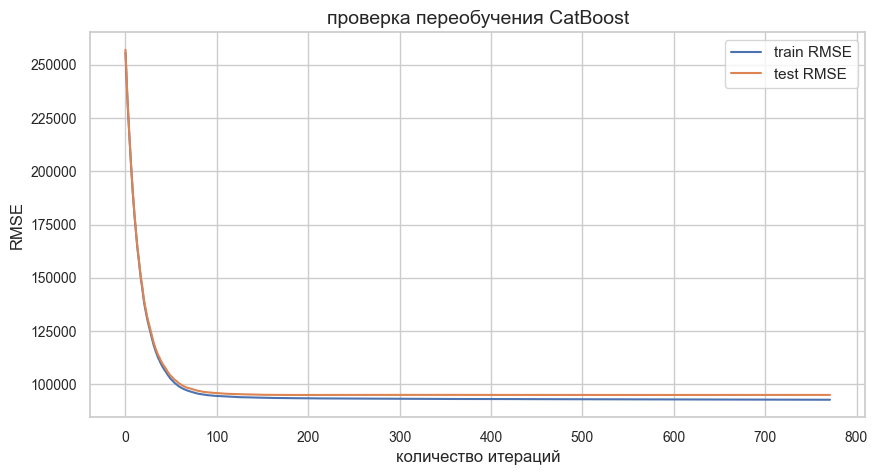

In [48]:
# берём обученную модель
model = best_models['catboost']

# рассчитываем rmse по итерациям
train_rmse = [
    mean_squared_error(y_train, pred) ** 0.5
    for pred in model.staged_predict(X_train)
]

test_rmse = [
    mean_squared_error(y_test, pred) ** 0.5
    for pred in model.staged_predict(X_test)
]

# строим график переобучения
plt.figure(figsize=(10, 5))
plt.plot(train_rmse, label='train RMSE')
plt.plot(test_rmse, label='test RMSE')

plt.xlabel('количество итераций')
plt.ylabel('RMSE')
plt.title('проверка переобучения CatBoost')
plt.legend()
plt.grid(True)
plt.show()

## Выводы 6. Финальная проверка



На отложенной тестовой выборке оптимизированная модель **CatBoost** показала следующие результаты:

- **MAE:** 75 756,68 ₽
- **RMSE:** 95 037,31 ₽
- **R²:** 0,874
- **Overpricing Rate:** 13,45%
- **Underpricing Loss:** 20,0 млн ₽

**Сравнение с валидацией:** MAE снизилась с 79 167,99 ₽ до 75 756,68 ₽, а R² увеличился с 0,856 до 0,874. Таким образом, на новых данных модель продемонстрировала даже более высокую точность.

**Проверка переобучения:** RMSE на обучающей и тестовой выборках быстро снижается и стабилизируется. Разрыв между кривыми остаётся небольшим, выраженного роста тестовой ошибки не наблюдается. Признаков существенного переобучения не выявлено.

**Итог:** CatBoost успешно прошёл финальную проверку и продемонстрировал хорошую способность к обобщению на новых данных. Модель можно рекомендовать для использования в качестве инструмента оценки стоимости автомобилей, сохранив экспертную проверку сделок с повышенным финансовым риском.

 # **Часть 7. Описание выводов и финальный вердикт**

**Задание 7.1**

Заполните краткую аналитическую записку на основе ваших данных.

**АНАЛИТИЧЕСКАЯ ЗАПИСКА ПО ПРОЕКТУ AUTOVALUE AI:**

1. Рекомендованная модель: [Название вашей лучшей модели, например]

2. Точность оценки: в среднем модель ошибается на [Ваше MAE] руб. Коэффициент детерминации равен[Ваше $R^2$], что подтверждает высокую надёжность прогнозов.

3. Безопасность бюджета: риск опасной переплаты (Overpricing >20%) зафиксирован на уровне [Ваш %]. Это позволяет стартапу сохранять маржинальность при выкупе.

4. Упущенная выгода: можем терять до [Сумма Underpricing Loss] руб. в месяц из-за занижения цены. Рекомендуется ручной пересмотр для премиум-сегмента.

5. Зоны риска: модель наиболее нестабильна в регионе [Ваш проблемный регион] и на марках [Ваши проблемные марки].

6. Какие гиперпараметры следует зафиксировать для интеграции в мобильное приложение.

---

## 7.1. Аналитическая записка по проекту AutoValue AI



1. **Рекомендуемая модель:** CatBoostRegressor, оптимизированная с помощью Optuna. Показала лучшие результаты среди трёх исследованных библиотек.

2. **Точность оценки:** на финальной тестовой выборке MAE составила **75 756,68 ₽**, R² — **0,874**. Модель объясняет 87,4% вариации стоимости автомобилей.

3. **Безопасность бюджета:** Overpricing Rate (>20%) составляет **13,45%**. Это означает, что примерно в 13 из 100 случаев модель существенно завышает стоимость автомобиля. Для таких сделок рекомендуется дополнительная проверка.

4. **Упущенная выгода:** Underpricing Loss составляет **19,99 млн ₽** на тестовой выборке. Это потенциальная недополученная выручка из-за существенной недооценки автомобилей, а не фактические ежемесячные убытки компании.

5. **Зоны риска:** наибольшая доля существенных ошибок наблюдается для **Toyota (25,66%), BMW (23,39%) и Tesla (23,31%)**. Среди регионов наиболее проблемными являются **Сибирь (22,53%) и СПб (22,10%)**. Для этих категорий рекомендуется дополнительная экспертная проверка.

6. **Гиперпараметры для интеграции:** рекомендуется зафиксировать найденные Optuna настройки CatBoost: `depth=4`, `iterations=772`, `learning_rate≈0.06799`, `l2_leaf_reg≈2.65064`, `loss_function='MAE'`, `random_seed=42`. Для приложения следует использовать сохранённую обученную модель вместе с неизменной схемой предобработки признаков.

**Финальный вердикт:** CatBoost продемонстрировал хорошую точность и отсутствие выраженного переобучения. Модель рекомендуется для внедрения в качестве инструмента поддержки решений, однако сделки с повышенным риском необходимо дополнительно проверять вручную. Для закупок с ограниченным бюджетом перспективной альтернативой остаётся квантильный CatBoost с `alpha=0.2`, снижающий вероятность опасных переплат.

In [52]:
print('Все ячейки успешно выполненны!')

Все ячейки успешно выполненны!
